In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv('/content/crop_condition_classification_3000_rows.csv')
df

,Soil_Moisture_Percent,Temperature_C,Humidity_Percent,Rainfall_mm_Week,Soil_pH,Soil_Nitrogen_mg_kg,Sunlight_Hours_Day,Crop_Condition
0,38.00,36.30,50.34,20.45,7.42,134.40,6.55,Healthy
1,61.75,39.60,66.69,6.43,7.76,33.65,7.23,Healthy
2,66.83,32.46,25.09,13.37,4.71,58.23,2.06,Healthy
3,65.16,34.66,47.39,5.49,7.61,105.82,5.95,Healthy
4,31.57,24.97,76.72,55.22,7.90,127.34,9.64,Healthy
...,...,...,...,...,...,...,...,...
2995,15.86,22.41,30.38,22.29,7.38,10.67,8.85,Moderate Stress
2996,86.46,22.68,23.92,4.94,7.40,81.03,8.90,Healthy
2997,45.44,29.47,53.67,8.44,7.12,111.92,2.54,Healthy
2998,54.17,33.65,62.04,4.32,4.98,110.20,4.67,Healthy


In [4]:
df.head()

,Soil_Moisture_Percent,Temperature_C,Humidity_Percent,Rainfall_mm_Week,Soil_pH,Soil_Nitrogen_mg_kg,Sunlight_Hours_Day,Crop_Condition
0,38.00,36.30,50.34,20.45,7.42,134.40,6.55,Healthy
1,61.75,39.60,66.69,6.43,7.76,33.65,7.23,Healthy
2,66.83,32.46,25.09,13.37,4.71,58.23,2.06,Healthy
3,65.16,34.66,47.39,5.49,7.61,105.82,5.95,Healthy
4,31.57,24.97,76.72,55.22,7.90,127.34,9.64,Healthy


In [5]:
df.tail()

,Soil_Moisture_Percent,Temperature_C,Humidity_Percent,Rainfall_mm_Week,Soil_pH,Soil_Nitrogen_mg_kg,Sunlight_Hours_Day,Crop_Condition
2995,15.86,22.41,30.38,22.29,7.38,10.67,8.85,Moderate Stress
2996,86.46,22.68,23.92,4.94,7.40,81.03,8.90,Healthy
2997,45.44,29.47,53.67,8.44,7.12,111.92,2.54,Healthy
2998,54.17,33.65,62.04,4.32,4.98,110.20,4.67,Healthy
2999,71.09,15.54,51.87,16.62,8.71,32.86,10.80,Healthy


In [6]:
df.describe()

,Soil_Moisture_Percent,Temperature_C,Humidity_Percent,Rainfall_mm_Week,Soil_pH,Soil_Nitrogen_mg_kg,Sunlight_Hours_Day
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,48.338863,27.583357,59.214610,14.589633,6.482137,72.353013,7.019520
std,23.637641,8.848625,22.439401,11.362669,1.315663,38.670237,2.884874
min,8.150000,12.000000,20.010000,0.120000,4.200000,5.000000,2.000000
25%,27.840000,19.947500,40.015000,6.017500,5.330000,39.277500,4.540000
50%,47.835000,28.035000,59.680000,11.760000,6.490000,72.170000,7.085000
75%,68.757500,35.152500,78.390000,20.255000,7.622500,105.117500,9.550000
max,89.970000,42.990000,97.970000,89.190000,8.800000,139.990000,12.000000


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error


In [10]:
x=df.drop('Crop_Condition',axis=1)
y=df['Crop_Condition']

In [11]:
from sklearn.preprocessing import LabelEncoder

In [12]:
model=RandomForestRegressor()


In [29]:
from sklearn.ensemble import RandomForestClassifier

# Encode categorical target strings to numeric values
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Instantiate and fit the classifier
model = RandomForestClassifier()
model.fit(x, y_encoded)

RandomForestClassifier()

In [32]:
soil = float(input('Enter the Soil Moisture Percent: ') or 0)
temp = float(input('Enter the Temperature C: ') or 0)
humidity = float(input('Enter the Humidity Percent: ') or 0)
rainfall = float(input('Enter the Rainfall mm Week: ') or 0)
ph = float(input('Enter the Soil pH: ') or 0)
nitrogen = float(input('Enter the Soil Nitrogen mg/kg: ') or 0)
sunlight = float(input('Enter the Sunlight Hours Day: ') or 0)

# Create the input dataframe
user=pd.DataFrame({
    'Soil_Moisture_Percent':[soil],
    'Temperature_C':[temp],
    'Humidity_Percent':[humidity],
    'Rainfall_mm_Week':[rainfall],
    'Soil_pH':[ph],
    'Soil_Nitrogen_mg_kg':[nitrogen],
    'Sunlight_Hours_Day':[sunlight]
})

# Predict using the classifier
pred_encoded = model.predict(user)

# Decode back to the textual label
pred_label = le.inverse_transform(pred_encoded)
print(f'\nPredicted Crop Condition: {pred_label[0]}')

Enter the Soil Moisture Percent: 44
Enter the Temperature C: 30
Enter the Humidity Percent: 60
Enter the Rainfall mm Week: 5
Enter the Soil pH: 7
Enter the Soil Nitrogen mg/kg: 66
Enter the Sunlight Hours Day: 4

Predicted Crop Condition: Healthy


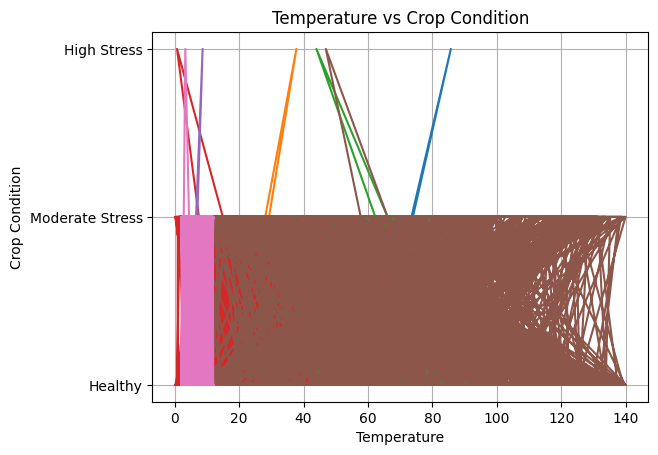

In [34]:
import matplotlib.pyplot as plt
plt.plot(x,y)
plt.xlabel('Temperature')
plt.ylabel('Crop Condition')
plt.title('Temperature vs Crop Condition')
plt.grid(True)
plt.show()